# Module 06: Gradient Descent, Optimizers, and Learning Rate Strategy

This notebook teaches **Gradient Descent, Optimizers, and Learning Rate Strategy** from basic intuition to practical deep-learning use.

Main coverage: loss surface, gradient descent, SGD, mini-batches, learning rate, momentum, RMSProp, Adam, AdamW, schedules, clipping.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Module Outline

* **Step 1: Loss surface**
* **Step 2: Gradient descent**
* **Step 3: Batch GD SGD Mini-batch GD**
* **Step 4: Learning rate**
* **Step 5: Momentum**
* **Step 6: Nesterov**
* **Step 7: AdaGrad**
* **Step 8: RMSProp**
* **Step 9: Adam and AdamW**
* **Step 10: Learning-rate schedules**
* **Step 11: Warmup**
* **Step 12: Gradient clipping**


## Step 2: Gradient descent

**What is it?** Gradient descent is the update rule that changes model parameters in the opposite direction of the loss gradient. The gradient points toward the direction where loss increases fastest, so moving against it usually reduces the loss.

**Where it is used:** It is the foundation behind nearly every neural-network optimizer. SGD, Momentum, RMSProp, Adam, AdamW, LAMB, and many other optimizers are variations of this basic idea.

**Why it matters:** Without gradient descent, the network would calculate loss but would not know how to improve weights. It is the mechanism that turns errors into parameter updates.

**Simple intuition:** Imagine standing on a hill in fog. The gradient tells the steepest uphill direction under your feet. Gradient descent takes a step downhill.

**Formula / rule:** $\theta_{new}=\theta_{old}-\eta\nabla_\theta L$ where $\eta$ is learning rate and $\nabla_\theta L$ is the gradient.

**Example:** If a weight has gradient +0.8 and learning rate 0.1, the weight moves down by 0.08. If the gradient is -0.8, the weight increases by 0.08.

**Common mistake:** Thinking gradient descent guarantees the global best solution. In deep networks it usually finds a useful low-loss region, not a mathematically guaranteed global minimum.


## Step 3: Batch GD, SGD, and Mini-batch GD

**What is it?** These are three ways to choose how much training data is used for one update. Batch gradient descent uses the full training set, SGD uses one example, and mini-batch gradient descent uses a small batch such as 32, 64, or 256 examples.

**Where it is used:** Mini-batch training is the standard in deep learning because it balances stable gradients, hardware efficiency, and update frequency.

**Why it matters:** The batch choice changes the noise in the gradient. Full-batch updates are stable but slow. One-example SGD is noisy. Mini-batches give useful noise while still using matrix operations efficiently.

**Simple intuition:** A full class vote is stable but slow. One student's opinion is fast but noisy. A small group gives a practical estimate.

**Formula / rule:** Full batch: gradient from all rows. SGD: gradient from one row. Mini-batch: gradient from selected rows.

**Example:** For 10,000 images and batch size 100, one epoch has 100 updates. Each update estimates the full gradient using 100 images.

**Common mistake:** Confusing batch size with epoch. Batch size is examples per update; epoch is one full pass through the training set.


## Step 4: Learning rate

**What is it?** Learning rate is the step size used when updating parameters. It decides how far the optimizer moves after reading the gradient.

**Where it is used:** It is set in every optimizer and is often the most important hyperparameter during training.

**Why it matters:** A learning rate that is too large can overshoot good solutions or make loss explode. A learning rate that is too small can make training painfully slow or stuck.

**Simple intuition:** The gradient tells direction; the learning rate tells stride length.

**Formula / rule:** $\theta_{new}=\theta_{old}-\eta g$ where $\eta$ is the learning rate and $g$ is the gradient.

**Example:** If gradient is 2.0, LR 0.001 changes the weight by 0.002; LR 0.5 changes it by 1.0.

**Common mistake:** Using a default learning rate without checking the loss curve. Bad LR can make a correct model look broken.


## Step 5: Momentum

**What is it?** Momentum adds a velocity term to gradient descent. Instead of using only the current gradient, the optimizer keeps a moving direction based on previous gradients.

**Where it is used:** It is common in SGD with momentum and appears conceptually inside Adam as first-moment estimation.

**Why it matters:** It speeds movement in directions that consistently reduce loss and reduces zig-zagging in steep narrow valleys.

**Simple intuition:** A ball rolling downhill does not forget its previous direction at every point. Momentum gives optimization that rolling behavior.

**Formula / rule:** $v_t=\beta v_{t-1}+g_t$, then $\theta_t=\theta_{t-1}-\eta v_t$.

**Example:** On an elongated loss surface, plain GD may bounce side to side; momentum smooths the path forward.

**Common mistake:** Setting momentum very high with a large learning rate can overshoot and make training unstable.


## Step 6: Nesterov momentum

**What is it?** Nesterov momentum is a momentum variant that looks ahead in the direction of the current velocity before calculating the gradient.

**Where it is used:** It is used as an alternative to classical momentum in some SGD training recipes.

**Why it matters:** The look-ahead gradient can correct the update before moving too far, often giving smoother optimization.

**Simple intuition:** Classical momentum says, 'move with current speed, then check slope.' Nesterov says, 'peek where this speed will take me, then correct.'

**Formula / rule:** Look-ahead point: $\theta-\eta\beta v$; gradient is evaluated near that look-ahead position.

**Example:** If momentum is about to overshoot a valley, Nesterov can sense the slope at the future point and reduce the wrong push.

**Common mistake:** Thinking Nesterov is a completely different optimizer. It is still momentum, but with look-ahead gradient evaluation.


## Step 7: AdaGrad

**What is it?** AdaGrad adapts the learning rate for each parameter by dividing by the square root of accumulated past squared gradients.

**Where it is used:** It is useful historically and for sparse features, where some parameters receive gradients rarely.

**Why it matters:** Parameters with frequent large gradients get smaller future steps; rare parameters can still receive relatively larger updates.

**Simple intuition:** AdaGrad gives each parameter its own step-size history.

**Formula / rule:** $G_t=G_{t-1}+g_t^2$, $\theta_t=\theta_{t-1}-\eta g_t/(\sqrt{G_t}+\epsilon)$.

**Example:** In text models with rare words, rare-word embeddings may benefit because their accumulated gradient history is smaller.

**Common mistake:** The accumulated sum only grows, so effective learning rates can shrink too much during long training.


## Step 8: RMSProp

**What is it?** RMSProp fixes AdaGrad's endlessly shrinking learning rate by using an exponential moving average of squared gradients instead of a full accumulated sum.

**Where it is used:** It is used in non-stationary or noisy optimization and is historically important for RNN training.

**Why it matters:** Recent gradients matter more than very old gradients, so the adaptive scale can keep changing during training.

**Simple intuition:** RMSProp remembers recent gradient size, not the entire lifetime of the parameter.

**Formula / rule:** $s_t=\rho s_{t-1}+(1-\rho)g_t^2$, $\theta_t=\theta_{t-1}-\eta g_t/(\sqrt{s_t}+\epsilon)$.

**Example:** If gradients were large early but become smaller later, RMSProp can recover a useful step size because old gradients decay.

**Common mistake:** Treating RMSProp's decay rate as unimportant. The decay controls how quickly the optimizer forgets old gradient magnitudes.


## Step 9: Adam and AdamW

**What is it?** Adam combines momentum-like first-moment tracking with RMSProp-like second-moment scaling. AdamW is Adam with weight decay applied separately from the gradient update.

**Where it is used:** Adam is a common default optimizer. AdamW is widely used for transformers, fine-tuning, and modern deep-learning training.

**Why it matters:** Adam handles noisy gradients well and adapts step sizes per parameter. AdamW makes regularization cleaner because weight decay is decoupled from Adam's adaptive gradient scaling.

**Simple intuition:** Adam asks two questions for each parameter: which direction have gradients been pointing, and how large have they usually been?

**Formula / rule:** Adam tracks $m_t$ for average gradient and $v_t$ for average squared gradient. AdamW additionally shrinks weights directly through decoupled weight decay.

**Example:** In transformer fine-tuning, AdamW with warmup and weight decay is often more stable than plain SGD.

**Common mistake:** Thinking AdamW means no tuning is needed. Learning rate, weight decay, betas, batch size, and schedule still matter.


## Step 10: Learning-rate schedules

**What is it?** A learning-rate schedule changes the learning rate during training instead of keeping it constant.

**Where it is used:** Schedules are used in CNNs, transformers, fine-tuning, large-batch training, and long training runs.

**Why it matters:** Large steps can help early exploration; smaller steps later help settle into a better solution. A schedule controls this transition.

**Simple intuition:** Training often needs big steps at the start and careful steps near the end.

**Formula / rule:** Common schedules: step decay, exponential decay, cosine decay, cyclic LR, OneCycle, ReduceLROnPlateau.

**Example:** Cosine decay starts high and smoothly lowers the LR; ReduceLROnPlateau lowers LR when validation stops improving.

**Common mistake:** Using a schedule without understanding total steps. A cosine schedule over the wrong number of steps can decay too early or too late.


## Step 11: Warmup

**What is it?** Warmup gradually increases the learning rate from a small value to the target value during the first part of training.

**Where it is used:** It is common in transformer training, large-batch training, and fine-tuning.

**Why it matters:** Early gradients can be unstable because weights and optimizer statistics are not settled. Warmup avoids large early updates.

**Simple intuition:** Warmup is like starting a car slowly before driving fast; it prevents sudden jerks at the beginning.

**Formula / rule:** Example: linearly increase LR from 0 to 1e-3 over the first 1,000 steps, then start decay.

**Example:** A transformer may use 5% of total steps for warmup before cosine decay.

**Common mistake:** Using warmup as a fix for every unstable run. Bad data, bad initialization, or too high final LR can still break training.


## Step 12: Gradient clipping

**What is it?** Gradient clipping limits the size of gradients before the optimizer updates parameters. It is used when gradients become extremely large and would cause a destructive update.

**Where it is used:** It is common in RNNs, sequence models, reinforcement learning, mixed-precision training, and any model where gradient spikes appear.

**Why it matters:** Exploding gradients can make weights jump too far, causing loss to become NaN or training to collapse. Clipping keeps the update within a safe range.

**Simple intuition:** If the gradient is a push, clipping says: push in the same direction, but do not push harder than this maximum allowed strength.

**Formula / rule:** Norm clipping: if $\|g\| > c$, replace $g$ with $g \cdot c/\|g\|$. Value clipping: cap each gradient component between fixed limits.

**Example:** If gradient vector is [30, 40], its norm is 50. With clip norm 5, it becomes [3, 4]. Direction stays the same, size becomes safe.

**Common mistake:** Using clipping to hide a deeper problem. If gradients constantly explode, also check learning rate, initialization, normalization, loss scale, and data outliers.


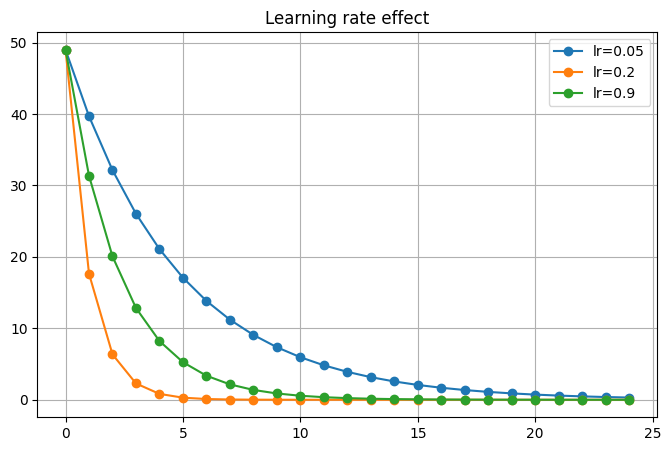

In [2]:
grad=lambda w:2*(w-3); loss=lambda w:(w-3)**2
for lr in [.05,.2,.9]:
 w=-4; hist=[]
 for _ in range(25): hist.append(loss(w)); w-=lr*grad(w)
 plt.plot(hist,marker='o',label=f'lr={lr}')
plt.legend(); plt.title('Learning rate effect'); plt.show()


## Research-Backed Coverage Expansion: Optimization and Learning-Rate Strategy

This expansion fills concepts commonly covered in deep-learning texts and courses such as the Deep Learning book, CS231n/CS224n, and Dive into Deep Learning. Each concept is written for learning flow: definition, where it is used, why it matters, and common mistakes.


### Objective Function vs Metric

**Definition:** The objective is the differentiable loss optimized during training; the metric is the human-facing score used to judge performance.

**Where it is used:** Every training loop and model-selection workflow.

**Why it matters:** A model may optimize cross-entropy while the team watches F1, AUC, or MAE.

**Common mistake:** Optimizing one quantity and expecting every metric to improve automatically.


### Ill-Conditioned Loss Surface

**Definition:** A surface where some directions are steep and others are flat.

**Where it is used:** Deep networks, especially with poor scaling or initialization.

**Why it matters:** Gradient descent can zig-zag or move slowly when curvature differs by direction.

**Common mistake:** Blaming only the optimizer when feature scaling or initialization is the real issue.


### Saddle Point

**Definition:** A point that is flat in some directions but not a true minimum.

**Where it is used:** High-dimensional neural-network optimization.

**Why it matters:** Deep networks often face saddle-like regions more than simple local minima.

**Common mistake:** Thinking every plateau is a local minimum.


### Gradient Noise

**Definition:** Randomness in mini-batch gradients compared with full-batch gradients.

**Where it is used:** SGD and mini-batch training.

**Why it matters:** Some noise helps escape poor regions, but too much noise makes training unstable.

**Common mistake:** Assuming larger batch size is always better.


### Momentum Buffer

**Definition:** A running velocity that smooths gradient updates.

**Where it is used:** SGD with momentum and Nesterov momentum.

**Why it matters:** It accelerates movement in consistent directions and reduces zig-zagging.

**Common mistake:** Setting momentum high without checking overshooting.


### Adaptive Learning Rates

**Definition:** Per-parameter learning-rate scaling based on gradient history.

**Where it is used:** AdaGrad, RMSProp, Adam, AdamW.

**Why it matters:** Different parameters can need different update sizes.

**Common mistake:** Thinking Adam removes the need to tune learning rate.


### Decoupled Weight Decay

**Definition:** AdamW applies weight decay separately from gradient-based Adam updates.

**Where it is used:** Modern transformer/CNN training.

**Why it matters:** It makes regularization behavior cleaner than L2 inside Adam.

**Common mistake:** Using Adam with L2 and assuming it is identical to AdamW.


### Learning-Rate Range Test

**Definition:** A diagnostic that tries increasing learning rates to find useful ranges.

**Where it is used:** Practical training setup.

**Why it matters:** It helps choose a starting learning rate before long runs.

**Common mistake:** Using the maximum stable LR directly instead of a safer value below it.


### Cosine Decay

**Definition:** A schedule that smoothly reduces the learning rate following a cosine curve.

**Where it is used:** CNNs, transformers, and long training runs.

**Why it matters:** It avoids sudden LR drops and often works well with warmup.

**Common mistake:** Using a schedule without enough total epochs for it to matter.


### Warm Restarts

**Definition:** Restarting a schedule to temporarily raise LR again.

**Where it is used:** SGDR-style training and exploration.

**Why it matters:** It can help explore new regions after settling.

**Common mistake:** Restarting too often so training never stabilizes.


### Gradient Norm Monitoring

**Definition:** Tracking total gradient size during training.

**Where it is used:** Debugging exploding/vanishing gradients.

**Why it matters:** It catches instability before loss becomes NaN.

**Common mistake:** Only watching loss and missing gradient explosions.


### Mixed Precision Optimizer Issues

**Definition:** Low precision can underflow small gradients unless loss scaling is used.

**Where it is used:** GPU training with float16/bfloat16.

**Why it matters:** It improves speed but needs numerical care.

**Common mistake:** Assuming mixed precision is only a speed setting.


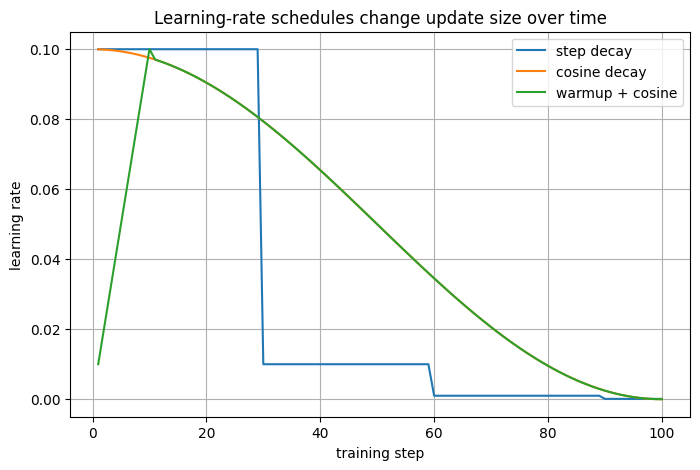

In [3]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
steps = np.arange(1, 101)
base_lr = 0.1
step_decay = base_lr * (0.1 ** (steps // 30))
cosine = base_lr * 0.5 * (1 + np.cos(np.pi * steps / steps.max()))
warmup_cosine = cosine.copy()
warmup_cosine[:10] = np.linspace(base_lr/10, base_lr, 10)
plt.plot(steps, step_decay, label='step decay')
plt.plot(steps, cosine, label='cosine decay')
plt.plot(steps, warmup_cosine, label='warmup + cosine')
plt.title('Learning-rate schedules change update size over time')
plt.xlabel('training step'); plt.ylabel('learning rate'); plt.legend();


## Algorithm and Dataset Expansion: Optimizers and Learning-Rate Strategy

This section connects the concepts to algorithms and datasets. For each module, the learner should understand what data shape is appropriate, which algorithm family fits the data, what metric to read, and what failure pattern to check.


### Optimizer Algorithm Map

| Algorithm | Core idea | Best first use | Watch out |
|---|---|---|---|
| Batch Gradient Descent | use all data for each update | convex demos and tiny data | slow on large data |
| SGD | one example per update | teaching and online learning | noisy updates |
| Mini-batch SGD | batch of examples per update | standard deep learning | batch size changes gradient noise |
| Momentum SGD | keeps velocity | CNNs and stable large-scale training | can overshoot |
| Nesterov Momentum | looks ahead before gradient | smoother momentum variant | harder to explain/debug |
| AdaGrad | adapts using accumulated squared gradients | sparse features | LR shrinks too much |
| RMSProp | moving average of squared gradients | non-stationary losses/RNN history | extra decay hyperparameter |
| Adam | momentum + adaptive scaling | strong default for many models | can generalize worse than SGD in some vision setups |
| AdamW | Adam with decoupled weight decay | transformers and modern fine-tuning | weight decay still needs tuning |
| Lion | sign-based momentum optimizer | newer large-model training experiments | not universal default |


### Dataset Explanation for This Module

Optimization is easiest to understand with a **synthetic regression loss surface** first, because the learner can see the path taken by each optimizer. Then use a **small classification dataset**, such as two-moons or digits, to connect optimizer behavior to real training curves.

Use synthetic data here because optimizer behavior should be isolated from messy data issues. Use real data later to show that learning rate, batch size, and optimizer choice change validation performance.


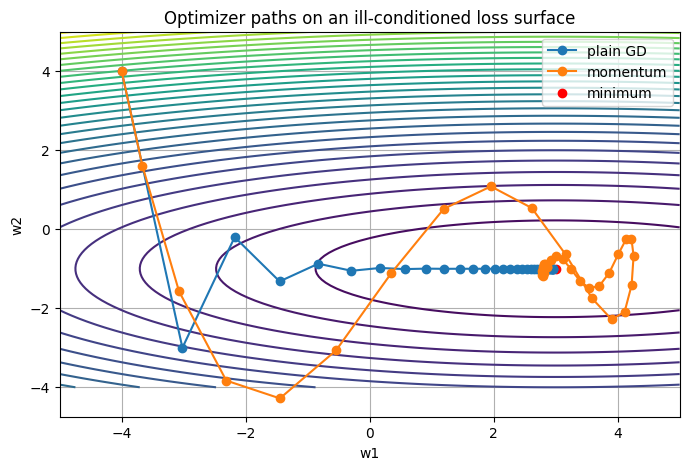

In [4]:
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(0)
def loss(w): return 0.2*(w[0]-3)**2 + 2.0*(w[1]+1)**2
def grad(w): return np.array([0.4*(w[0]-3), 4.0*(w[1]+1)])
def run(method, lr=.25, steps=35, beta=.8):
    w=np.array([-4.0,4.0]); v=np.zeros(2); path=[w.copy()]
    for _ in range(steps):
        g=grad(w)
        if method=='sgd':
            w=w-lr*g
        elif method=='momentum':
            v=beta*v+g
            w=w-lr*v
        path.append(w.copy())
    return np.array(path)
sgd=run('sgd',lr=.35); mom=run('momentum',lr=.12)
x=np.linspace(-5,5,120); y=np.linspace(-4,5,120)
X,Y=np.meshgrid(x,y); Z=0.2*(X-3)**2+2*(Y+1)**2
plt.contour(X,Y,Z,levels=30)
plt.plot(sgd[:,0],sgd[:,1],'o-',label='plain GD')
plt.plot(mom[:,0],mom[:,1],'o-',label='momentum')
plt.scatter([3],[-1],c='red',label='minimum')
plt.title('Optimizer paths on an ill-conditioned loss surface')
plt.xlabel('w1'); plt.ylabel('w2'); plt.legend();


**Metric meaning:** the useful outputs are not only final loss. Look at path smoothness, oscillation, speed toward the minimum, gradient norm, and whether the loss becomes unstable.


## Complete Concept and Algorithm Coverage: Module 06 — Optimizers

This section is a fuller checklist for the module. It is written so the learner can see not only the main concept, but also related algorithms, variants, correct datasets, metrics, and common failure modes.


| Area | Concepts / algorithms | What the student must understand |
|---|---|---|
| Gradient basics | full-batch GD, SGD, mini-batch SGD, stochastic gradient noise | The update uses gradient direction, but the amount of data used per update changes speed, noise, and hardware efficiency. |
| Momentum family | classical momentum, Nesterov accelerated gradient, dampening, momentum buffer | Momentum is not another loss; it stores velocity so repeated gradient directions accumulate. |
| Adaptive optimizers | AdaGrad, RMSProp, Adadelta, Adam, Adamax, Nadam, AdamW | Adaptive methods scale each parameter differently using gradient history. |
| Large-batch optimizers | LARS, LAMB, linear scaling rule, gradient accumulation | Large-batch training needs LR scaling and layerwise adaptation to avoid unstable updates. |
| Newer optimizer ideas | Lion, Lookahead, SAM / sharpness-aware minimization, EMA of weights | These change update direction, smooth weights, or prefer flatter minima; they are advanced tools, not default magic. |
| Second-order methods | Newton method, quasi-Newton, L-BFGS, Hessian-vector product | They use curvature information, but full Hessians are usually too expensive for deep nets. |
| Learning-rate policy | constant LR, step decay, exponential decay, cosine decay, OneCycle, cyclic LR, warmup, warm restarts, ReduceLROnPlateau | The LR schedule often matters as much as optimizer choice. |
| Stability controls | gradient clipping by value, clipping by norm, loss scaling, mixed precision, NaN checks | These prevent numerical failure and exploding updates. |
| Diagnostics | loss curve, gradient norm, update-to-weight ratio, LR range test, train/validation gap | Optimizer quality should be judged by training stability and validation behavior. |
| Dataset choice | synthetic surface, two-moons, digits, CIFAR-style images | Start with synthetic surfaces for intuition, then real datasets for validation behavior. |


### Correct learning flow

Teach optimizers in this order: gradient descent → SGD noise → mini-batch training → momentum → adaptive learning rates → AdamW → schedules → clipping → advanced optimizers. Do not introduce AdamW before the learner understands what a gradient update is.


In [5]:
import pandas as pd
optimizer_map = pd.DataFrame({
    'optimizer':['SGD','SGD+Momentum','RMSProp','Adam','AdamW','LAMB','SAM'],
    'main_extra_state':['none','velocity','avg squared grad','1st+2nd moment','1st+2nd moment + decoupled decay','layerwise trust ratio','two-step perturbation'],
    'typical_use':['simple baseline','CNN training','RNN history','general default','transformers/fine-tuning','large-batch training','flat-minima experiments']
})
display(optimizer_map)


,optimizer,main_extra_state,typical_use
0,SGD,none,simple baseline
1,SGD+Momentum,velocity,CNN training
2,RMSProp,avg squared grad,RNN history
3,Adam,1st+2nd moment,general default
4,AdamW,1st+2nd moment + decoupled decay,transformers/fine-tuning
5,LAMB,layerwise trust ratio,large-batch training
6,SAM,two-step perturbation,flat-minima experiments


## Module 06 Summary

This module covered **Gradient Descent, Optimizers, and Learning Rate Strategy** from foundation to advanced orientation. Review each step until you can explain what it is, where it is used, why it matters, and how the code/visual connects to the idea.
